### Prof. Alfio Ferrara

# Pesare le parole

##  Metodologie informatiche nelle discipline umanistiche
##### A.A. 2026/2027

---

Abbiamo diviso il testo in token. Ora dobbiamo decidere **quali numeri** mettere nel vettore di ogni documento: nelle colonne ci sono le parole, ma cosa scriviamo nelle caselle?

## Dal corpus alla matrice

Lavoriamo sui 100 testi del dataset delle città: 20 per ciascuno dei cinque climi (tropicale, desertico, mediterraneo, temperato, polare). Tokenizziamo con spaCy, teniamo solo i token alfabetici in minuscolo e costruiamo la tabella dei conteggi, con un documento per riga e una parola per colonna.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy

nlp = spacy.load('it_core_news_lg')

with open('data/clima_citta.json') as f:
    dataset = json.load(f)

nomi = [voce['citta'] for voce in dataset]
clima = pd.Series([voce['clima'] for voce in dataset], index=nomi)

def token_alfabetici(testo):
    return [t.text.lower() for t in nlp.tokenizer(testo) if t.is_alpha]

documenti = {voce['citta']: token_alfabetici(voce['testo']) for voce in dataset}

vocabolario = sorted({p for parole in documenti.values() for p in parole})

def conta(parole, vocabolario):
    posizione = {p: i for i, p in enumerate(vocabolario)}
    riga = np.zeros(len(vocabolario))
    for p in parole:
        if p in posizione:
            riga[posizione[p]] += 1
    return riga

conteggi = pd.DataFrame([conta(documenti[n], vocabolario) for n in nomi], index=nomi, columns=vocabolario)
print(conteggi.shape[0], 'documenti,', conteggi.shape[1], 'parole')

100 documenti, 608 parole


Ogni documento è ora un vettore con 608 componenti. Vediamo le prime colonne per alcune città.

In [2]:
conteggi.loc[['Singapore', 'Riyad', 'Reykjavik'], ['a', 'caldo', 'e', 'freddo', 'il', 'neve', 'piogge', 'sono']].astype(int)

,a,caldo,e,freddo,il,neve,piogge,sono
Singapore,1,1,3,0,0,0,1,1
Riyad,0,1,2,0,1,0,0,0
Reykjavik,1,0,4,1,2,1,0,2


## Conteggi e lunghezza dei documenti

Con le città avevamo visto che la distanza euclidea guarda i valori e il coseno guarda le proporzioni. Per i testi la differenza ha un nome concreto: **la lunghezza**. Un documento lungo ripete le parole molte più volte di uno breve anche se parla della stessa cosa.

Simuliamo il caso estremo. Aggiungiamo alla tabella un testo di Singapore **copiato due volte di seguito**, e confrontiamolo con l'originale.

In [3]:
def coseno(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

def euclidea(a, b):
    return np.linalg.norm(np.asarray(a) - np.asarray(b))

originale = conteggi.loc['Singapore']
raddoppiato = conta(documenti['Singapore'] * 2, vocabolario)

print('euclidea:', round(euclidea(originale, raddoppiato), 2))
print('coseno:  ', round(coseno(originale, raddoppiato), 2))

euclidea: 6.08
coseno:   1.0


### Lo stesso testo, due risposte

- Per la distanza euclidea il testo raddoppiato è lontano dall'originale. Perché?
- Per il coseno sono identici. Cosa ci dice dell'argomento dei due testi?
- Se usassimo la distanza euclidea per cercare testi simili, quali documenti verrebbero favoriti?
- Nel nostro dataset le lunghezze sono quasi uguali (circa 28 parole). In un archivio di lettere, verbali e romanzi?

## Frequenze relative

Il rimedio più diretto è lo stesso che abbiamo usato in L06 con le lettere: dividere ciascun conteggio per il **numero totale di parole** del documento. Otteniamo la **frequenza relativa** (*term frequency*, **tf**): la quota del testo occupata da ciascuna parola.

$$\text{tf}(t, d) = \frac{\text{conteggio di } t \text{ in } d}{\text{numero di parole in } d}$$

Ogni riga somma ora a 1, qualunque sia la lunghezza.

In [4]:
tf = conteggi.div(conteggi.sum(axis=1), axis=0)

print('somma delle righe:', tf.sum(axis=1).unique().round(6))
print('euclidea:', round(euclidea(tf.loc['Singapore'], conta(documenti['Singapore'] * 2, vocabolario) / (2 * len(documenti['Singapore']))), 6))

somma delle righe: [1. 1. 1. 1. 1. 1. 1. 1. 1.]
euclidea: 0.0


Ora possiamo chiederci quali sono le parole **più importanti** di ciascun documento, intendendo per importanti quelle con la frequenza relativa più alta.

In [5]:
def parole_principali(tabella, nome, k=6):
    return tabella.loc[nome].sort_values(ascending=False).head(k).round(3)

for nome in ['Singapore', 'Riyad', 'Reykjavik']:
    print(nome)
    print(parole_principali(tf, nome).to_string())
    print()

Singapore
e              0.097
pomeridiani    0.032
fa             0.032
una            0.032
umido          0.032
anno           0.032

Riyad
è           0.067
e           0.067
assente     0.033
quasi       0.033
estrema     0.033
quaranta    0.033

Reykjavik
e            0.133
sono         0.067
il           0.067
a            0.033
frequente    0.033
sole         0.033



### Sono davvero le parole importanti?

- Guardate le liste: quante delle parole principali dicono qualcosa sul clima della città?
- Le parole principali di Singapore e Reykjavik sono molto diverse o molto simili?
- Cosa avevamo scoperto alla fine di L06 sulle parole in comune tra testi di climi diversi?

## Quanto si assomigliano i documenti?

Calcoliamo la similarità del coseno tra tutte le coppie di documenti e la mostriamo come una mappa: ogni punto è una coppia, il colore dice quanto sono simili. Ordiniamo i documenti per clima, così le città dello stesso clima stanno in blocchi consecutivi lungo la diagonale.

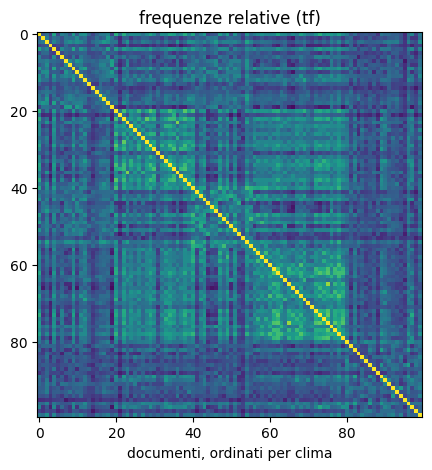

In [6]:
def similarita_documenti(tabella):
    X = tabella.values
    X = X / np.linalg.norm(X, axis=1, keepdims=True)
    return pd.DataFrame(X @ X.T, index=tabella.index, columns=tabella.index)

ordine = clima.sort_values(kind='stable').index

def mappa(sim, titolo, ax):
    ax.imshow(sim.loc[ordine, ordine], cmap='viridis', vmin=0, vmax=1)
    ax.set_title(titolo)
    ax.set_xlabel('documenti, ordinati per clima')

fig, ax = plt.subplots(figsize=(5.5, 5))
sim_tf = similarita_documenti(tf)
mappa(sim_tf, 'frequenze relative (tf)', ax)
plt.show()

Per riassumere la mappa in due numeri, confrontiamo la similarità media tra documenti dello **stesso clima** con quella tra documenti di **climi diversi**.

In [7]:
def riassunto(sim):
    stesso = clima.values[:, None] == clima.values[None, :]
    diagonale = np.eye(len(sim), dtype=bool)
    return {
        'stesso clima': round(sim.values[stesso & ~diagonale].mean(), 3),
        'climi diversi': round(sim.values[~stesso].mean(), 3),
    }

riassunto(sim_tf)

{'stesso clima': 0.415, 'climi diversi': 0.324}

### Cosa vediamo nella mappa

- Si vedono dei blocchi lungo la diagonale? Quanto sono netti rispetto al resto?
- Il fondo della mappa è chiaro anche fuori dai blocchi: documenti di climi diversi risultano molto simili. Da dove viene questa somiglianza?
- Confrontate i due numeri: la differenza tra «stesso clima» e «climi diversi» è grande?

## Parole comuni e parole specifiche

Il problema è chiaro: le parole che compaiono in **quasi tutti** i documenti (*e*, *sono*, *le*, *con*) hanno frequenza alta ma non distinguono un documento da un altro. Le parole che compaiono in **pochi** documenti (*neve*, *deserto*, *monsoni*) sono quelle che contano per sapere di cosa si parla.

Una parola è tanto più **specifica** quanto meno documenti la usano. Misuriamo questo con la **document frequency** (**df**): in quanti documenti compare almeno una volta.

In [8]:
N = len(conteggi)
df = (conteggi > 0).sum()

df.sort_values(ascending=False).head(15)

e          100
con         70
sono        68
le          66
è           59
il          58
piogge      55
estati      54
inverni     52
a           40
di          39
gli         36
la          35
anno        29
ha          28
dtype: int64

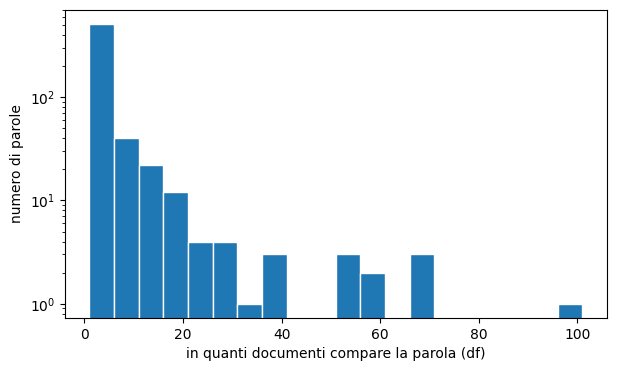

355 parole su 608 compaiono in un solo documento


In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df, bins=range(1, 102, 5), edgecolor='white')
ax.set_xlabel('in quanti documenti compare la parola (df)')
ax.set_ylabel('numero di parole')
ax.set_yscale('log')
plt.show()

print(int((df == 1).sum()), 'parole su', len(df), 'compaiono in un solo documento')

### Comuni o specifiche?

- Quali parole compaiono in più documenti? Sono quelle che ci aspettavamo?
- Che forma ha l'istogramma? Cosa ci dice sul vocabolario?
- Una parola che compare in un solo documento è molto specifica. È anche *utile* per confrontare due documenti? Pensate al nome della città.

## IDF: pesare la specificità

Vogliamo un peso che sia **alto per le parole rare e vicino a zero per quelle onnipresenti**. L'**inverse document frequency** (**idf**) fa proprio questo:

$$\text{idf}(t) = \log \frac{N}{\text{df}(t)}$$

dove $N$ è il numero di documenti. Se una parola compare in tutti i documenti, $\text{df} = N$ e l'idf vale $\log 1 = 0$. Se compare in uno solo, l'idf vale $\log N$, il massimo possibile. Il logaritmo smorza le differenze: passare da 1 a 2 documenti conta più che passare da 50 a 51.

In [10]:
idf = np.log(N / df)

esempio = pd.DataFrame({'df': df, 'idf': idf.round(2)}).loc[['e', 'sono', 'piogge', 'estati', 'caldo', 'neve', 'deserto', 'monsoni', 'singapore']]
esempio

,df,idf
e,100,0.00
sono,68,0.39
piogge,55,0.60
estati,54,0.62
caldo,19,1.66
neve,19,1.66
deserto,7,2.66
monsoni,2,3.91
singapore,1,4.61


### Cosa misura l'idf

- Quanto vale l'idf di *e*? E quello di *singapore*? Dove cadono le altre parole?
- *piogge* compare in molti testi: il suo peso è alto o basso? È una parola «sul clima»: la penalizziamo a ragione?
- Se il corpus fosse fatto solo di testi sul clima, l'idf di *clima* sarebbe alto o basso? Cosa dipende dal corpus?
- Cosa succederebbe all'idf di una parola se aggiungessimo 1000 testi di cucina?

## tf-idf

Mettiamo insieme le due cose. Una parola è **importante per un documento** se compare spesso *in quel documento* (tf alta) e in *pochi altri* (idf alta):

$$\text{tf-idf}(t, d) = \text{tf}(t, d) \cdot \text{idf}(t)$$

Il prodotto si calcola colonna per colonna: ogni colonna della tabella tf viene moltiplicata per l'idf della sua parola.

In [11]:
tfidf = tf * idf

for nome in ['Singapore', 'Riyad', 'Reykjavik']:
    print(nome)
    print(parole_principali(tfidf, nome).to_string())
    print()

Singapore
poco         0.149
singapore    0.149
altra        0.149
preavviso    0.149
variano      0.149
fa           0.113

Riyad
assente       0.154
marcata       0.154
estrema       0.154
facilmente    0.154
supera        0.154
riyad         0.154

Reykjavik
reykjavik    0.154
bui          0.154
frequente    0.130
illumina     0.117
freddo       0.107
settimane    0.100



### Cosa è cambiato nelle parole principali

- Le liste di prima contenevano *e*, *a*, *le*. Cosa c'è adesso?
- Le parole di Riyad e Reykjavik ora distinguono le due città?
- Compaiono nomi di città o parole rarissime in cima alla lista. Aiutano a capire il clima? A che cosa servirebbero, invece?
- Il tf-idf ha sistemato il problema delle parole grammaticali senza una lista di stop word. Qual è la differenza tra i due approcci?

## I documenti, con il nuovo peso

Ripetiamo il confronto tra tutte le coppie di documenti con i vettori tf-idf e mettiamo la mappa accanto a quella di prima.

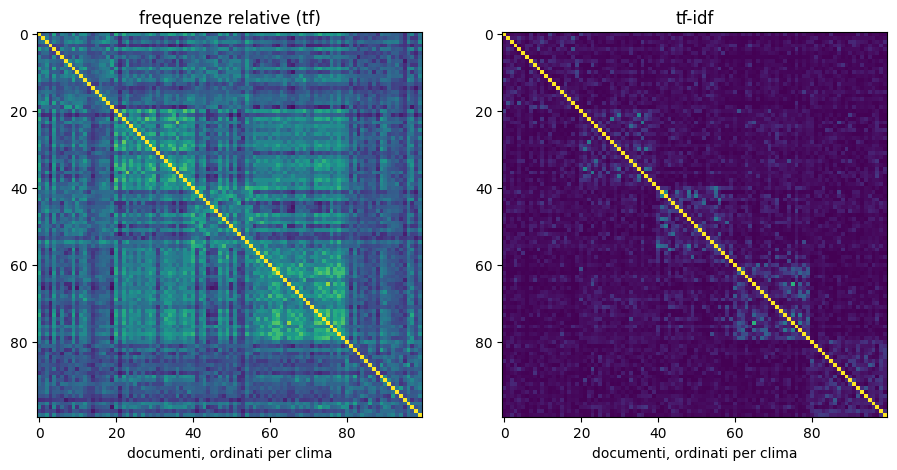

tf:     {'stesso clima': 0.415, 'climi diversi': 0.324}
tf-idf: {'stesso clima': 0.094, 'climi diversi': 0.035}


In [12]:
sim_tfidf = similarita_documenti(tfidf)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
mappa(sim_tf, 'frequenze relative (tf)', ax1)
mappa(sim_tfidf, 'tf-idf', ax2)
plt.show()

print('tf:    ', riassunto(sim_tf))
print('tf-idf:', riassunto(sim_tfidf))

### Prima e dopo

- Che differenza c'è tra lo sfondo della prima mappa e quello della seconda? Dove è finita la somiglianza «di fondo»?
- I blocchi dello stesso clima sono più o meno riconoscibili? Tutti i climi in ugual modo?
- Il rapporto tra similarità dentro il clima e fuori è cambiato? Confrontate i numeri.
- Alcuni climi risultano più compatti di altri. Cosa significa che le descrizioni di un clima sono più «uniformi» di quelle di un altro?

Una verifica più concreta: per ogni documento cerchiamo il più simile tra *tutti gli altri* e controlliamo se ha lo stesso clima.

In [13]:
def vicino_stesso_clima(sim):
    s = sim.values.copy()
    np.fill_diagonal(s, -1)
    vicino = s.argmax(axis=1)
    return (clima.values[vicino] == clima.values).mean()

print('tf:    ', vicino_stesso_clima(sim_tf))
print('tf-idf:', vicino_stesso_clima(sim_tfidf))

tf:     0.82
tf-idf: 0.89


## Dove stanno i documenti nello spazio

Ogni documento è un punto in uno spazio a 608 dimensioni, e non possiamo disegnarlo. In L06 abbiamo guardato **proiezioni** scegliendo due colonne alla volta, ma qui sarebbe come guardare i documenti attraverso due sole parole.

Esiste un modo migliore di scegliere due assi: invece di prendere due colonne, costruiamo **due direzioni nuove** (combinazioni di tutte le colonne) lungo le quali i documenti si disperdono il più possibile. Questo metodo si chiama **analisi delle componenti principali** (PCA). Ci serve solo il suo risultato: ogni documento riceve due coordinate, che usiamo per il disegno.

Normalizziamo i vettori a lunghezza 1, come fa il coseno, e proiettiamo.

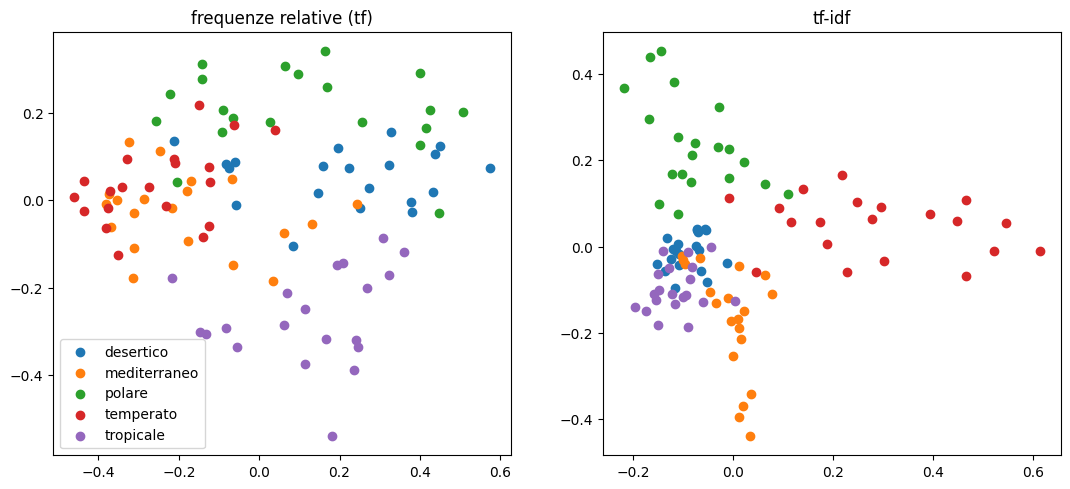

quota di dispersione catturata dai due assi, tf:     0.156
quota di dispersione catturata dai due assi, tf-idf: 0.061


In [14]:
from sklearn.decomposition import PCA

def proietta(tabella):
    X = tabella.values / np.linalg.norm(tabella.values, axis=1, keepdims=True)
    pca = PCA(n_components=2).fit(X)
    return pd.DataFrame(pca.transform(X), index=tabella.index, columns=['x', 'y']), pca.explained_variance_ratio_

def disegna_spazio(coordinate, titolo, ax):
    for c in sorted(clima.unique()):
        punti = coordinate[clima == c]
        ax.scatter(punti['x'], punti['y'], label=c)
    ax.set_title(titolo)

piano_tf, var_tf = proietta(tf)
piano_tfidf, var_tfidf = proietta(tfidf)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
disegna_spazio(piano_tf, 'frequenze relative (tf)', ax1)
disegna_spazio(piano_tfidf, 'tf-idf', ax2)
ax1.legend()
plt.show()

print('quota di dispersione catturata dai due assi, tf:    ', round(var_tf.sum(), 3))
print('quota di dispersione catturata dai due assi, tf-idf:', round(var_tfidf.sum(), 3))

### Cosa ci dice il disegno

- Nel grafico di sinistra i colori si separano? Quali climi sono più riconoscibili?
- E nel grafico di destra? Dove si sono spostati i documenti di un clima rispetto a prima?
- I due assi catturano una frazione piccola della dispersione totale (guardate i numeri stampati). Cosa significa per l'affidabilità di quello che vediamo? Due punti vicini nel disegno sono necessariamente vicini nello spazio vero?
- Vi aspettavate che il disegno separasse bene i climi? Cosa fa sì che testi che parlano di *caldo* siano in punti diversi?
- Un punto isolato lontano dagli altri: andate a leggere quel testo. Cosa lo rende diverso?

In [15]:
punti = piano_tfidf.copy()
punti['clima'] = clima
punti.round(2).sort_values('x').head(5)

,x,y,clima
Tromsø,-0.22,0.37,polare
Port Moresby,-0.20,-0.14,tropicale
Kiruna,-0.17,0.44,polare
Lagos,-0.17,-0.15,tropicale
Norilsk,-0.17,0.29,polare


## Cosa abbiamo imparato

1. Per costruire il vettore di un documento servono dei **numeri**, e la scelta cambia il confronto. I conteggi grezzi dipendono dalla lunghezza, quindi usiamo frequenze relative (**tf**) o il coseno.
2. La tf da sola dà peso alle parole **più frequenti**, che sono quelle grammaticali: tutti i documenti diventano simili tra loro.
3. L'**idf** misura quanto una parola è specifica del corpus: vale 0 se compare ovunque, è massima se compare in un solo documento. Dipende dal **corpus**, non dal singolo testo.
4. Il prodotto **tf-idf** valorizza le parole frequenti nel documento *e* rare nel corpus. Ripulisce il confronto senza una lista di stop word.
5. Nello spazio dei documenti il tf-idf produce gruppi più riconoscibili, ma una proiezione a due assi resta una **vista parziale** di uno spazio con centinaia di dimensioni.

Abbiamo ora un modo di rappresentare i documenti. Nel prossimo notebook lo usiamo per rispondere a un bisogno informativo: **cercare** i documenti più vicini a una domanda.